# Load the trained model


In [16]:
%run train.ipynb

Selected Numeric Features: ['roomservice', 'spa', 'vrdeck']
Selected Categorical Features: ['cryosleep']
['roomservice', 'spa', 'vrdeck', 'cryosleep']
(5215, 4) (1739, 4) (1739, 4)
(5215,) (1739,) (1739,)
0:	test: 0.8017422	best: 0.8017422 (0)	total: 1.02ms	remaining: 2.04s
200:	test: 0.8111809	best: 0.8118661 (144)	total: 197ms	remaining: 1.76s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8118660614
bestIteration = 144

Shrink model to first 145 iterations.
train      acc=0.7749  f1=0.7862  auc=0.8306
validation acc=0.7596  f1=0.7726  auc=0.8119
test       acc=0.7734  f1=0.7826  auc=0.8197


## Metric functions
The positive class is the larger label in `model.classes_`, which means the passenger was transported.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def get_confusion_matrix(X, y):
    predictions = model.predict(X).astype(int).ravel()
    return confusion_matrix(y, predictions, labels=model.classes_)


def calculate_metrics(matrix):
    tn, fp, fn, tp = matrix.ravel()

    accuracy = (tp + tn) / matrix.sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "accuracy": accuracy,
        "error_rate": 1 - accuracy,
        "precision": precision,
        "recall": recall,
        "sensitivity": recall,  # sensitivity and recall are the same formula
        "specificity": tn / (tn + fp),
        "f1": 2 * precision * recall / (precision + recall),
    }


def plot_confusion_matrix(matrix, set_name, class_names):
    display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
    display.plot(cmap="Blues", colorbar=False)
    plt.title(f"Confusion matrix: {set_name} set")
    plt.show()

# Evaluate every data set

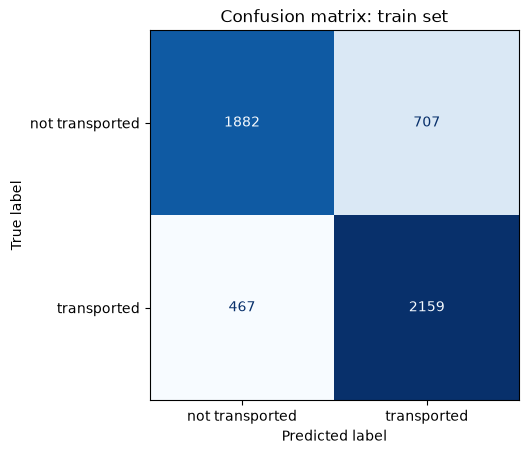

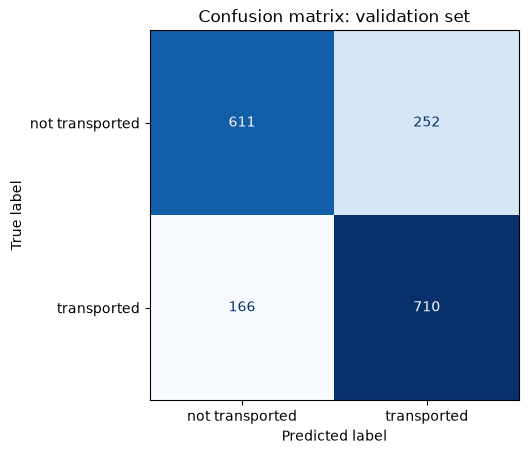

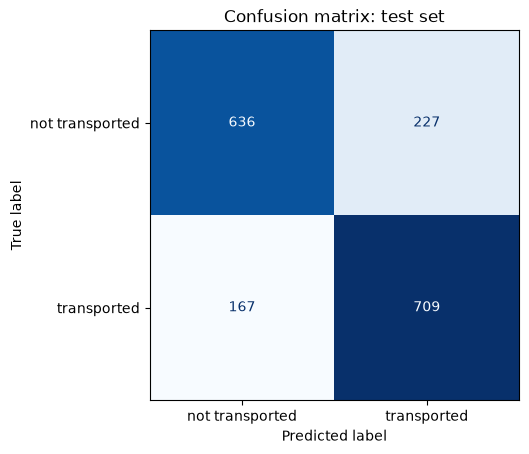

,TN,FP,FN,TP,accuracy,error_rate,precision,recall,sensitivity,specificity,f1
train,1882.0,707.0,467.0,2159.0,0.7749,0.2251,0.7533,0.8222,0.8222,0.7269,0.7862
validation,611.0,252.0,166.0,710.0,0.7596,0.2404,0.7380,0.8105,0.8105,0.7080,0.7726
test,636.0,227.0,167.0,709.0,0.7734,0.2266,0.7575,0.8094,0.8094,0.7370,0.7826


In [15]:
data_sets = {
    "train": (X_train_cb, y_train),
    "validation": (X_val_cb, y_val),
    "test": (X_test_cb, y_test),
}
class_names = [f"not {target}", target]

results = {}
for set_name, (X, y) in data_sets.items():
    matrix = get_confusion_matrix(X, y)
    plot_confusion_matrix(matrix, set_name, class_names)
    results[set_name] = calculate_metrics(matrix)

pd.DataFrame(results).T.round(4)